# M04-2 | QAT 的 conv + BN：BN 留著，另外折一份給 weight 量化

PTQ 在 `prepare_pt2e` 就把 BN 折進 conv（M04-1）。QAT 不能這樣做：訓練時 BN 要繼續用**當下 batch 的統計**，
折掉就沒有 BN 可以訓練了。但我們又希望 weight 的 fake quant 量化的是「折完的 weight」，訓練時看到的量化誤差才和部署時一樣。

`prepare_qat_pt2e` 的做法是在 conv 與 BN 周圍插入一小段子圖。為什麼這樣插，M04 概覽的「QAT：weight 的 fake quant 該量化哪一份 weight」
一節有完整推理，出處是部落格〈[Convolution 與 BatchNorm 的融合大法](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/)〉；
這本 notebook 把那段推理對到圖上。

- **A.** 同一個 conv_bn_relu：`prepare_pt2e` 與 `prepare_qat_pt2e` 的圖差在哪。
- **B.** 讀 QAT 子圖：為什麼這樣插，每個多出來的 op 在算什麼。
- **C.** `convert_pt2e` 之後：QAT 的 BN 也折掉了；以及什麼情況下折不掉。

In [1]:
import copy
from collections import Counter

import torch
import torch.nn.functional as F

from common.graph_utils import qdq_nodes, short
from common.models import ConvBnReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)

和 M04-1 一樣，先讓 BN 有真實的 running stats。QAT 要用 training IR export（`export_module(..., train=True)`），
BN 才是訓練版本的 op；quantizer 要傳 `is_qat=True`，插的才是 fake quant：

In [2]:
model = ConvBnReLU(3, 8).train()
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)

ptq = prepare_pt2e(export_module(copy.deepcopy(model).eval(), example_inputs()),
                   get_xnnpack_quantizer(is_per_channel=True)[0])
qat = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True),
                       get_xnnpack_quantizer(is_per_channel=True, is_qat=True)[0])

## A. prepare_pt2e 與 prepare_qat_pt2e 的圖差在哪

兩張圖各有哪些 op、幾個（`call_module` 寫成模組類別）：

In [3]:
def op_counter(g):
    return Counter(type(g.get_submodule(n.target)).__name__ if n.op == "call_module" else short(n.target)
                   for n in g.graph.nodes if n.op in ("call_function", "call_module") and n.name != "_guards_fn")


c_ptq, c_qat = op_counter(ptq), op_counter(qat)
table([[k, c_ptq.get(k, 0), c_qat.get(k, 0)] for k in sorted(set(c_ptq) | set(c_qat))], ["op", "prepare_pt2e", "prepare_qat_pt2e"])

op,prepare_pt2e,prepare_qat_pt2e
FusedMovingAvgObsFakeQuantize,0,3
HistogramObserver,2,0
PerChannelMinMaxObserver,1,0
add,0,1
add_,0,1
batch_norm,0,1
conv2d,1,1
div,0,2
mul,0,1
relu,1,1


In [4]:
assert c_ptq["batch_norm"] == 0 and c_qat["batch_norm"] == 1
assert c_qat["FusedMovingAvgObsFakeQuantize"] == 3

- **PTQ**：`batch_norm` 已經折掉，量化點是三個 observer（只收統計，不改數值）。
- **QAT**：`batch_norm` 還在，多了 `mul`、`div`、`sqrt`、`reshape` 這串算 BN scale 的 op；量化點換成三個 `FusedMovingAvgObsFakeQuantize`（會真的 fake quant）。
  它名字裡的「fused」和本章的 conv + BN 無關，指的是「更新 min／max、算 scale／zero point、quantize → dequantize」三步合成一顆 ATen kernel。這顆 kernel 算 scale 的方式有個坑，M06-3 處理。
- 量化點的位置相同：輸入 `x`、weight、relu 的輸出。差別在 weight 那一個量化的是什麼，看 B 段。
- `add_` 是 BN 的 `num_batches_tracked += 1`，train 模式的 export 都有（M00-2）。

## B. 讀 QAT 子圖

先回顧概覽的結論（$\sigma$ 是標準差、已含 $\varepsilon$；下標 $B$ 是這個 batch 的統計，沒有下標是 running stats）：

- **weight 的 fake quant 要量化 $W_{\text{inf}} = \gamma W / \sigma$**：它是部署時真正量化的 weight，而且 running stats 變化慢，量化的格子不會每個 batch 跳一次。
  改量化 $W_{\text{train}} = \gamma W / \sigma_B$ 的話，格子跟著 $\sigma_B$ 跳，訓練不穩。
- **BN 仍要用 batch 統計訓練**。量化白皮書的「慢版」多算一次沒量化的 conv 來拿 $\mu_B$、$\sigma_B$；
  PyTorch 預設的「近似版」`_forward_approximate` 省掉這次 conv，`prepare_qat_pt2e` 用的就是它：

$$
s = \frac{\gamma}{\sigma}, \qquad
y = \mathrm{BN}_{\text{batch}}\!\Big( \frac{\mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W \cdot s)\big)}{s} \Big) \tag{1}
$$

把整張 QAT 圖畫出來，式 (1) 的每一項標在對應的 node 底下：

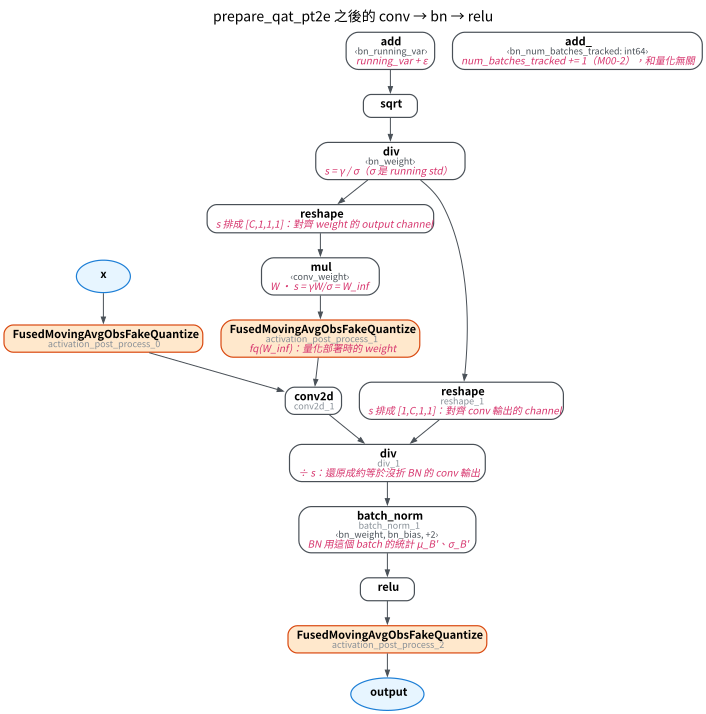

In [5]:
nodes = {n.name: n for n in qat.graph.nodes}
fq_w = next(n for n in qat.graph.nodes if n.op == "call_module" and n.args[0].target == torch.ops.aten.mul.Tensor)
notes = {
    "add": "running_var + ε",
    "add_": "num_batches_tracked += 1（M00-2），和量化無關",
    "div": "s = γ / σ（σ 是 running std）",
    "reshape": "s 排成 [C,1,1,1]：對齊 weight 的 output channel",
    "mul": "W · s = γW/σ = W_inf",
    fq_w.name: "fq(W_inf)：量化部署時的 weight",
    "reshape_1": "s 排成 [1,C,1,1]：對齊 conv 輸出的 channel",
    "div_1": "÷ s：還原成約等於沒折 BN 的 conv 輸出",
    "batch_norm_1": "BN 用這個 batch 的統計 μ_B'、σ_B'",
}
draw(qat, notes=notes, title="prepare_qat_pt2e 之後的 conv → bn → relu")

In [6]:
assert nodes["batch_norm_1"].args[0] is nodes["div_1"]  # BN 吃的是 ÷ s 之後的 conv 輸出
assert fq_w.args[0] is nodes["mul"]  # weight 的 fake quant 吃的是 W · s

從上往下讀：

1. `add` → `sqrt` → `div` 用 running var 算出每個 channel 的 $s = \gamma/\sigma$。
2. `reshape` → `mul` 算出 $W \cdot s = W_{\text{inf}}$，交給 weight 的 fake quant。conv 本身不帶 bias，BN 的 $\beta$ 之後才加。
3. conv 的輸出是用折過的 weight 算的，等於「已經乘上 $s$」。`reshape_1` → `div_1` 再除以 $s$，還原成約等於沒折 BN 的 conv 輸出。
4. 還原之後，後面的 `batch_norm` 就像沒量化時一樣運作：從輸入算這個 batch 的平均 $\mu_B'$、標準差 $\sigma_B'$ 來正規化，也照常更新 running stats。

**為什麼第 3 步要除以 $s$？** 把第 4 步的 BN 展開（$z$ 是量化 conv 的輸出）：

$$
\gamma\,\frac{z/s - \mu_B'}{\sigma_B'} + \beta
= z \cdot \frac{\sigma}{\sigma_B'} + \Big(\beta - \frac{\gamma\,\mu_B'}{\sigma_B'}\Big) \tag{2}
$$

右邊正是慢版的式子：量化 $W_{\text{inf}}$ 的 conv，乘上修正項 $\sigma/\sigma_B'$，再加 batch 統計的 bias。
除以 $s$ 讓 BN 自己算出修正項，所以不必另外算一次沒量化的 conv；代價是 $\mu_B'$、$\sigma_B'$ 取自**量化後**的 conv 輸出，不是慢版用的沒量化的版本。

用圖上的 fake quant 模組與參數驗證式 (2) 兩邊相等：

In [7]:
params = dict(qat.named_parameters())
fq_x_mod = copy.deepcopy(qat.get_submodule(nodes["conv2d_1"].args[0].target))  # 複本：fake quant 在 forward 時會更新狀態
fq_w_mod = copy.deepcopy(qat.get_submodule(fq_w.target))
w, gamma, beta = params["conv.weight"], params["bn.weight"], params["bn.bias"]
sigma = torch.sqrt(qat.get_buffer("bn.running_var") + 1e-5)  # running std，含 ε（BatchNorm2d 預設 1e-5）
s = gamma / sigma

x = torch.randn(16, 3, 16, 16) * 2 + 1
with torch.no_grad():
    z = F.conv2d(fq_x_mod(x), fq_w_mod(w * s.reshape(-1, 1, 1, 1)), None, padding=1)  # 量化 conv 的輸出
    u = z / s.reshape(1, -1, 1, 1)
    left = F.batch_norm(u, None, None, gamma, beta, training=True, eps=1e-5)  # 式 (2) 左邊：圖的做法
    mu_b, sigma_b = u.mean((0, 2, 3)), torch.sqrt(u.var((0, 2, 3), unbiased=False) + 1e-5)
    right = z * (sigma / sigma_b).reshape(1, -1, 1, 1) + (beta - gamma * mu_b / sigma_b).reshape(1, -1, 1, 1)  # 右邊
print(f"式 (2) 左右兩邊的最大差：{float((left - right).abs().max()):.1e}")
assert torch.allclose(left, right, atol=1e-5)

式 (2) 左右兩邊的最大差：4.8e-07


兩邊只差浮點誤差：近似版就是「用量化後的 batch 統計」的慢版。兩者在數值上差多少，是 M04-3 的主題。

## C. convert_pt2e 之後：QAT 的 BN 也折掉了

`convert_pt2e` 沒有 `is_qat` 之類的參數，PTQ 與 QAT 走同一條路：先把 observer／fake quant 換成 Q/DQ，再嘗試折 BN
（torchao 內部的 `_fold_conv_bn_qat`，M02 概覽列過 convert 的步驟）：

- 圖上沒有 BN（PTQ 在 prepare 時已經折掉）：直接略過。
- 有 BN：比對「`prepare_qat_pt2e` 產生的 conv + BN 子圖 + Q/DQ」這個 pattern，比對成功才折。比對失敗就原樣留著 BN，不報錯、不警告。

第三條路徑是故意的錯誤示範：`prepare_qat_pt2e` 配上 `is_qat=False` 的 quantizer。

In [8]:
wrong = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True),
                         get_xnnpack_quantizer(is_per_channel=True, is_qat=False)[0])
rows = []
for name, g in [("PTQ", ptq), ("QAT", qat), ("QAT，但 quantizer 的 is_qat=False", wrong)]:
    converted = convert_pt2e(copy.deepcopy(g))
    counts = op_counter(converted)
    folded_bias = any("weight_bias" in str(n.target) for n in converted.graph.nodes if n.op == "get_attr")
    rows.append([name, counts.get("batch_norm", 0), counts.get("conv2d", 0), counts.get("relu", 0),
                 len(qdq_nodes(converted)), folded_bias])
table(rows, ["路徑", "batch_norm", "conv2d", "relu", "q/dq 數", "有折出來的 bias"])

路徑,batch_norm,conv2d,relu,q/dq 數,有折出來的 bias
PTQ,0,1,1,5,True
QAT,0,1,1,5,True
QAT，但 quantizer 的 is_qat=False,1,1,1,5,False


In [9]:
assert [r[1] for r in rows] == [0, 0, 1]
assert rows[0][2:] == rows[1][2:]  # PTQ 與 QAT convert 之後同形

- **前兩個 row**：QAT 的圖 convert 之後，BN 真的折進 conv，和 PTQ 一樣只剩 conv2d、relu 與 q/dq。後端拿到的圖不知道、也不需要知道走的是哪一條路。
- **第三個 row**：`is_qat=False` 的 quantizer 插的是普通 observer，不是 fake quant，子圖結構不同，convert 之後 BN 還留在圖上。
  推論（這裡沒有追到比對失敗的確切環節）：是 pattern 結構不符。自己拼出來的 FakeQuantize + conv + BN 圖同理，不符合支援的 pattern 就折不了。

## 小結

- QAT 的 BN 不在 prepare 時折掉，而是留著用 batch 統計訓練；`prepare_qat_pt2e` 另外插一段子圖，讓 weight 的 fake quant 量化折過的 weight $W \cdot s$。
- `convert_pt2e` 才真的折 BN，最後的圖和 PTQ 同形。
- 能不能折取決於 prepare 產生的圖結構（包含 quantizer 的 `is_qat`），不是 convert 的參數。